# 06 - Batch fitting, the output files, two full days

How to run the pipeline on whole files, what it writes, and how to turn the CSV into
parameter time series.

**Runtime:** a few seconds if notebook 00 already fitted the example, about 1.5 minutes
otherwise.

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 1. Running the batch fit

`runFiles(dataDir, outputDir, ...)` fits every `VDF_eas_forFitting_*.h5` file in
`dataDir` (or those listed in `fileNames`). Each file is fitted in a process pool and
written to `per_file/<stem>_fit.csv`; at the end everything is merged into
`summary.csv`.

| argument | default | meaning |
|---|---|---|
| `breakDir` | `dataDir` | where `<stem>_two_population_crossing.csv` lives (notebook 03) |
| `workers` | 4 | parallel processes (one epoch each; one BLAS thread per process) |
| `objective` | `'poisson'` | `'poisson'` or `'chi2'` (notebook 07) |
| `plotEvery` | 0 | save the four-panel figure of every N-th epoch to `plots/<stem>/` |
| `resume` | `True` | skip files whose CSV already has one row per epoch |
| `freeHaloDrift` | `True` | halo parallel drift free within $\pm 0.2$ halo widths; `False` (`--fix-halo-drift`) pins it at 0 |

From a terminal, at the repository root:

```
PYTHONPATH=src python -m evdf_poisson.runner --data-dir examples/example_data \
    --out results/fitting/example_run_poisson --workers 4 --plot-every 1
```

With `resume`, rerunning the same command after an interruption only fits what is
missing. To refit, use a fresh output directory or `resume=False` / `--no-resume`.

In [2]:
from evdf_poisson.runner import runFiles

summary = runFiles(EXAMPLE_DIR, RESULTS_DIR, workers=4, plotEvery=1)   # resumes if notebook 00 already ran
sorted(path.relative_to(RESULTS_DIR).as_posix() for path in RESULTS_DIR.rglob('*') if path.is_file())[:8]

2026-10-05 19:10:21  1 files, 4 workers, objective=poisson, halo drift free -> /disk/plasma/xw2/SO-EAS-eVDF_Fitting/results/fitting/example_run_poisson


2026-10-05 19:10:21  [1/1] VDF_eas_forFitting_20230404005008_20230404011908_1min.h5 already complete, skipping


2026-10-05 19:10:21  merged 1 file CSVs -> summary.csv (30 rows)


['per_file/VDF_eas_forFitting_20230404005008_20230404011908_1min_fit.csv',
 'plots/VDF_eas_forFitting_20230404005008_20230404011908_1min/epoch0000.png',
 'plots/VDF_eas_forFitting_20230404005008_20230404011908_1min/epoch0001.png',
 'plots/VDF_eas_forFitting_20230404005008_20230404011908_1min/epoch0002.png',
 'plots/VDF_eas_forFitting_20230404005008_20230404011908_1min/epoch0003.png',
 'plots/VDF_eas_forFitting_20230404005008_20230404011908_1min/epoch0004.png',
 'plots/VDF_eas_forFitting_20230404005008_20230404011908_1min/epoch0005.png',
 'plots/VDF_eas_forFitting_20230404005008_20230404011908_1min/epoch0006.png']

## 2. The columns of `summary.csv`

| column | meaning |
|---|---|
| `epoch_index`, `epoch_ns`, `time_iso` | epoch index within the file, time as ns since 1970 and as text |
| `n_sc` | independent electron density from RPW (cm$^{-3}$), used to bound the core and strahl densities |
| `n_c`, `u_par_c_cms`, `T_par_c_eV`, `T_perp_c_eV` | core density, parallel drift (cm/s, spacecraft frame along **B**), temperatures |
| `n_h`, `u_par_h_cms`, `T_par_h_eV`, `T_perp_h_eV`, `kappa_h` | halo density, parallel drift (0 when the run used `freeHaloDrift=False`), temperatures, kappa |
| `n_b`, `u_par_b_cms`, `T_par_b_eV`, `T_perp_b_eV`, `kappa_b` | strahl; `n_b` = 0 and NaN temperatures when no strahl was fitted |
| `n_total` | $n_c + n_h + n_b$ |
| `deviance_per_dof` | Poisson deviance over all valid pixels / (pixels - free parameters) |
| `red_chi2` | classical reduced chi-square on the detected (counts > 0) pixels with $\sigma = f/\sqrt{C}$ |
| `objective` | `poisson` or `chi2` |
| `strahl_sign`, `strahl_tier` | PAD verdict: +1 / -1 / 0 and `par_strong`, `anti_weak`, `quasi_iso`, ... |
| `break_energy_eV`, `break_source` | break used by the fit; `crossing` (from the CSV) or `proxy_7.7T` (fallback) |
| `pad_beta_par`, `pad_beta_anti`, `pad_paw_par`, `pad_paw_anti`, `pad_deficit` | PAD contrasts, widths (deg) and deficit flag |
| `pinned_params` | free parameters that ended on the edge of their range (`;`-separated) |
| `runtime_s`, `error` | seconds per epoch; non-empty `error` = the epoch failed (row kept) |
| `fit_params_json` | all 14 raw parameters (CGS) as JSON, enough to redraw the model |

EAS densities can differ from RPW by a calibration factor that depends on the
instrument state. Treat `n_sc` as the reference for absolute densities.

In [3]:
summary['time'] = pd.to_datetime(summary['time_iso'])
summary[['time_iso', 'n_sc', 'n_total', 'n_c', 'n_h', 'n_b', 'strahl_tier', 'break_source', 'deviance_per_dof', 'pinned_params', 'runtime_s']].round(3)

,time_iso,n_sc,n_total,n_c,n_h,n_b,strahl_tier,break_source,deviance_per_dof,pinned_params,runtime_s
0,2023-04-04 00:50:08,28.047,10.724,10.483,0.182,0.059,anti_strong,crossing,0.539,v_th_perp_h;u_par_b,18.496
1,2023-04-04 00:51:08,27.472,10.499,10.200,0.165,0.134,anti_strong,crossing,0.582,v_th_par_h;v_th_perp_h;u_par_b,13.903
2,2023-04-04 00:52:08,26.917,10.755,10.452,0.165,0.138,anti_strong,crossing,0.570,v_th_par_h;u_par_b,17.187
3,2023-04-04 00:53:08,26.599,10.783,10.408,0.169,0.207,anti_strong,crossing,0.573,v_th_par_h;u_par_b,15.747
4,2023-04-04 00:54:08,25.987,10.448,10.122,0.159,0.167,anti_strong,crossing,0.605,v_th_par_h;u_par_b,10.619
5,2023-04-04 00:55:08,26.141,10.442,9.976,0.131,0.334,anti_strong,crossing,0.563,u_par_b;kappa_b,11.100
6,2023-04-04 00:56:08,26.570,10.399,10.105,0.140,0.153,anti_strong,crossing,0.602,u_par_b,9.703
7,2023-04-04 00:57:08,26.761,10.610,10.249,0.195,0.166,anti_strong,crossing,0.586,v_th_par_h;v_th_perp_h;u_par_b,9.233
8,2023-04-04 00:58:08,24.404,9.791,9.514,0.096,0.182,anti_strong,crossing,0.626,v_th_par_h;u_par_b,22.551
9,2023-04-04 00:59:08,24.095,9.900,9.607,0.177,0.117,anti_strong,crossing,0.548,v_th_perp_h;u_par_b,19.617


## 3. Parameter time series

The same plotting code works for thirty minutes or for a month (section 6 applies it
to two days). Strahl quantities are masked where no strahl was fitted.

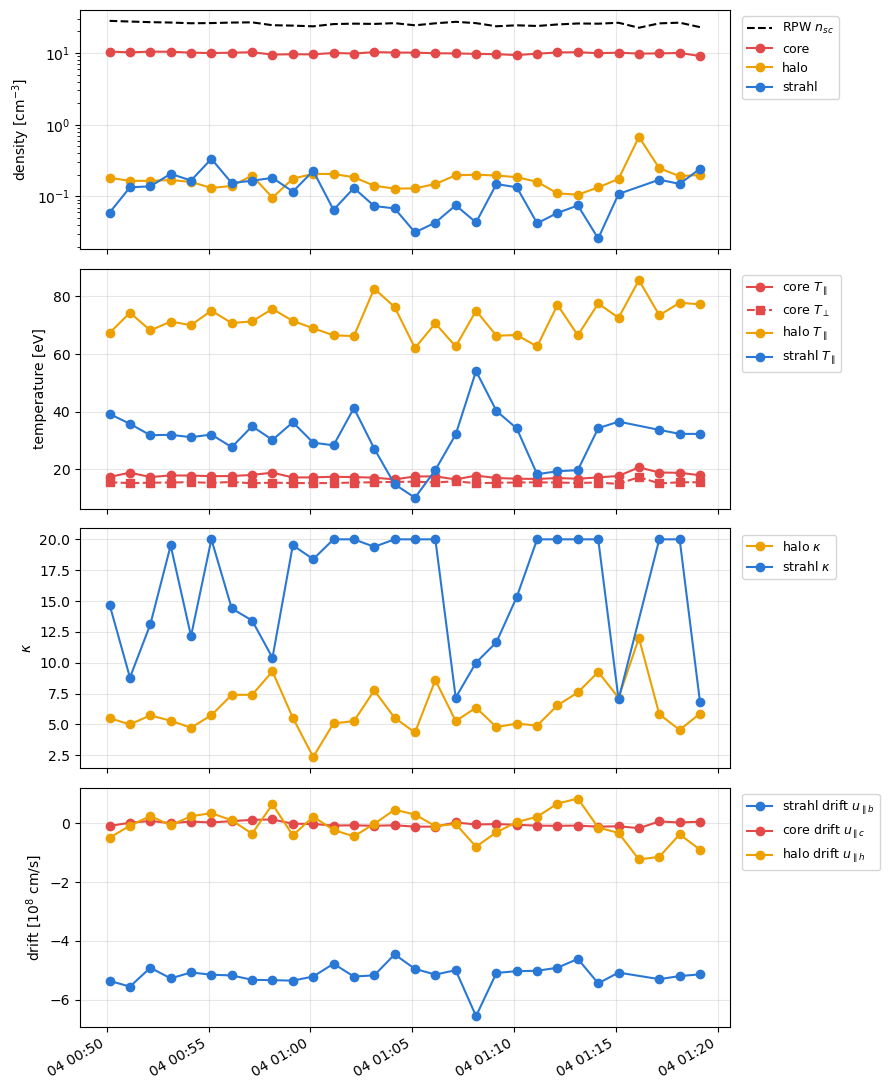

In [4]:
hasStrahl = summary['n_b'] > 0
fig, axes = plt.subplots(4, 1, figsize=(9, 11), sharex=True)

axes[0].plot(summary['time'], summary['n_sc'], 'k--', label='RPW $n_{sc}$')
axes[0].plot(summary['time'], summary['n_c'], 'o-', color='#e34948', label='core')
axes[0].plot(summary['time'], summary['n_h'], 'o-', color='#eda100', label='halo')
axes[0].plot(summary['time'][hasStrahl], summary['n_b'][hasStrahl], 'o-', color='#2a78d6', label='strahl')
axes[0].set_yscale('log'); axes[0].set_ylabel('density [cm$^{-3}$]')

axes[1].plot(summary['time'], summary['T_par_c_eV'], 'o-', color='#e34948', label=r'core $T_\parallel$')
axes[1].plot(summary['time'], summary['T_perp_c_eV'], 's--', color='#e34948', label=r'core $T_\perp$')
axes[1].plot(summary['time'], summary['T_par_h_eV'], 'o-', color='#eda100', label=r'halo $T_\parallel$')
axes[1].plot(summary['time'][hasStrahl], summary['T_par_b_eV'][hasStrahl], 'o-', color='#2a78d6', label=r'strahl $T_\parallel$')
axes[1].set_ylabel('temperature [eV]')

axes[2].plot(summary['time'], summary['kappa_h'], 'o-', color='#eda100', label=r'halo $\kappa$')
axes[2].plot(summary['time'][hasStrahl], summary['kappa_b'][hasStrahl], 'o-', color='#2a78d6', label=r'strahl $\kappa$')
axes[2].set_ylabel(r'$\kappa$')

axes[3].plot(summary['time'][hasStrahl], summary['u_par_b_cms'][hasStrahl] / 1e8, 'o-', color='#2a78d6', label=r'strahl drift $u_{\parallel b}$')
axes[3].plot(summary['time'], summary['u_par_c_cms'] / 1e8, 'o-', color='#e34948', label=r'core drift $u_{\parallel c}$')
axes[3].plot(summary['time'], summary['u_par_h_cms'] / 1e8, 'o-', color='#eda100', label=r'halo drift $u_{\parallel h}$')
axes[3].set_ylabel(r'drift [$10^8$ cm/s]')
for ax in axes:
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9); ax.grid(alpha=0.3)
fig.autofmt_xdate(); fig.tight_layout()

## 4. Fit quality and pinned parameters

- `deviance_per_dof` is the number to compare between epochs. It is **not** expected to
  be 1: at low expected counts a perfect model has a deviance well below 1 per pixel,
  so the typical value depends on how bright the plasma is. Look for outliers within a
  data set, not for a fixed threshold (notebook 08 has a calibrated version).
- `red_chi2` is for comparison with the chi-square literature only.
- `pinned_params` lists the parameters decided by their range. Frequent and harmless:
  `v_th_perp_h` on its lower limit (the halo width is degenerate with its density; the
  limit picks the physical corner), `u_par_b` on the lower edge of its +/-20 % lock,
  `kappa_b` at its ceiling (weakly constrained). A pinned `n_c`, `v_th_par_c` or `n_h`
  deserves a look at the figure.

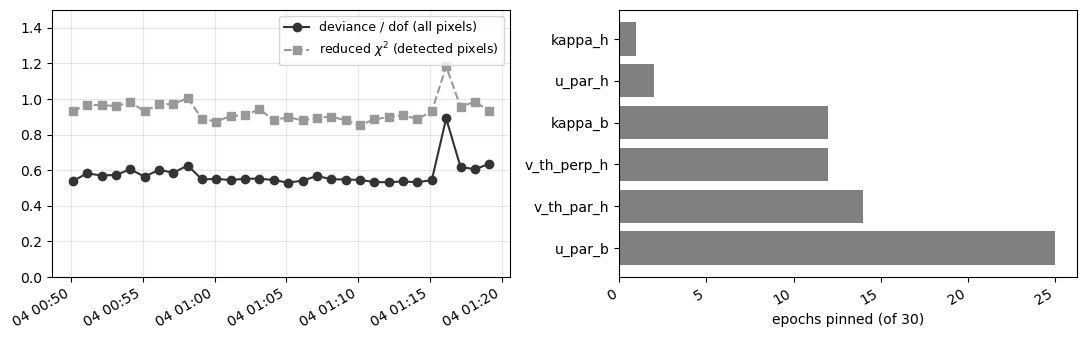

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(summary['time'], summary['deviance_per_dof'], 'o-', color='0.2', label='deviance / dof (all pixels)')
axes[0].plot(summary['time'], summary['red_chi2'], 's--', color='0.6', label=r'reduced $\chi^2$ (detected pixels)')
axes[0].set_ylim(0, 1.5); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
pinnedCounts = summary['pinned_params'].fillna('').str.split(';').explode().value_counts().drop('', errors='ignore')
axes[1].barh(pinnedCounts.index, pinnedCounts.values, color='0.5'); axes[1].set_xlabel('epochs pinned (of %d)' % len(summary))
fig.autofmt_xdate(); fig.tight_layout()

## 5. Single epochs, figures, your own data

- **One epoch with its figure.** Python: `fitOneEpoch(file, epochIndex,
  plotPath='epoch.png', breakEnergyEv=...)`. Terminal:
  `PYTHONPATH=src python -m evdf_poisson.plotting --chunk <h5> --epoch 20 --break-energy 139`.
- **Redraw a stored fit.** `fit_params_json` holds everything needed (notebook 01 does
  exactly that).
- **Your own interval.** Three commands, detailed in notebook 02:
  `preprocess_main(start_time, end_time, psd_source='soar', shift_SCPOT=True, scpot_file=..., output_dir=D)`,
  then `python src/compute_break_energy_crossing.py --vdf-dir D --output-dir D`,
  then `python -m evdf_poisson.runner --data-dir D --out results/fitting/<name> --workers N`.
  Keep the file-name pattern: the runner derives the break-energy file name from it.
- **Cost.** A six-hour file (~360 epochs) fits in about 10 minutes on 16 workers, with
  a few hundred MB per worker.

## 6. Two full days: 2023-04-04 and 2023-04-05

The example subset is half an hour out of a two-day run: 2 850 one-minute epochs in
eight six-hour files, fitted with the same code in about 12 minutes on 32 cores. The
preprocessed files (4.8 GB) are not distributed (`workshop/README.md` shows how to
rebuild them). The fit
results ship in `results/fitting/example_days_2023-04-04_05/summary.csv`, so this
section runs offline.

In [6]:
days = pd.read_csv(DAYS_DIR / 'summary.csv')
days['time'] = pd.to_datetime(days['time_iso'])
days = days[days['error'].fillna('') == ''].sort_values('time').reset_index(drop=True)
print(f'{len(days)} epochs, {days["time"].iloc[0]} .. {days["time"].iloc[-1]}')
print('strahl verdicts:', days['strahl_tier'].value_counts(normalize=True).round(3).to_dict())
print('break source:', days['break_source'].value_counts().to_dict())
print('deviance/dof: median %.3f, 5-95 %% %.3f-%.3f' % (days['deviance_per_dof'].median(), days['deviance_per_dof'].quantile(0.05), days['deviance_per_dof'].quantile(0.95)))

2849 epochs, 2023-04-04 00:00:08 .. 2023-04-05 23:59:09
strahl verdicts: {'anti_strong': 0.888, 'anti_weak': 0.097, 'quasi_iso': 0.016}
break source: {'crossing': 2749, 'proxy_7.7T': 100}
deviance/dof: median 0.631, 5-95 % 0.548-0.733


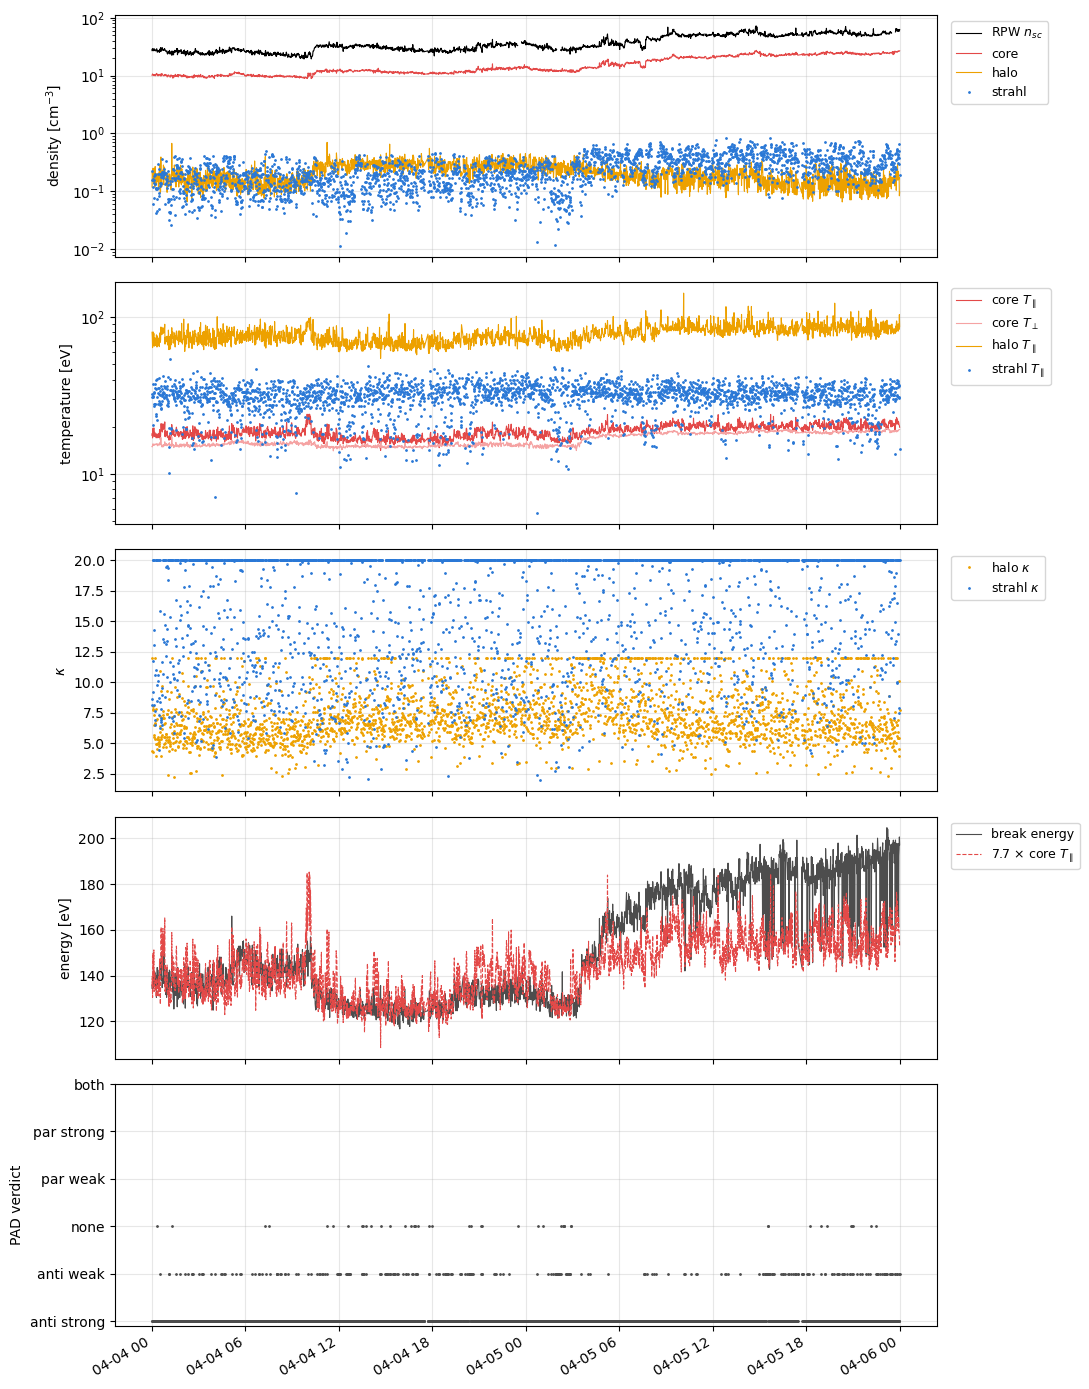

In [7]:
hasStrahl = days['n_b'] > 0
fig, axes = plt.subplots(5, 1, figsize=(11, 14), sharex=True)
axes[0].plot(days['time'], days['n_sc'], 'k-', linewidth=0.8, label='RPW $n_{sc}$')
axes[0].plot(days['time'], days['n_c'], '-', color='#e34948', linewidth=0.8, label='core')
axes[0].plot(days['time'], days['n_h'], '-', color='#eda100', linewidth=0.8, label='halo')
axes[0].plot(days['time'][hasStrahl], days['n_b'][hasStrahl], '.', color='#2a78d6', markersize=2, label='strahl')
axes[0].set_yscale('log'); axes[0].set_ylabel('density [cm$^{-3}$]')
axes[1].plot(days['time'], days['T_par_c_eV'], '-', color='#e34948', linewidth=0.8, label=r'core $T_\parallel$')
axes[1].plot(days['time'], days['T_perp_c_eV'], '-', color='#f5a3a3', linewidth=0.8, label=r'core $T_\perp$')
axes[1].plot(days['time'], days['T_par_h_eV'], '-', color='#eda100', linewidth=0.8, label=r'halo $T_\parallel$')
axes[1].plot(days['time'][hasStrahl], days['T_par_b_eV'][hasStrahl], '.', color='#2a78d6', markersize=2, label=r'strahl $T_\parallel$')
axes[1].set_yscale('log'); axes[1].set_ylabel('temperature [eV]')
axes[2].plot(days['time'], days['kappa_h'], '.', color='#eda100', markersize=2, label=r'halo $\kappa$')
axes[2].plot(days['time'][hasStrahl], days['kappa_b'][hasStrahl], '.', color='#2a78d6', markersize=2, label=r'strahl $\kappa$')
axes[2].set_ylabel(r'$\kappa$')
axes[3].plot(days['time'], days['break_energy_eV'], '-', color='0.3', linewidth=0.8, label='break energy')
axes[3].plot(days['time'], 7.7 * days['T_par_c_eV'], '--', color='#e34948', linewidth=0.8, label=r'7.7 $\times$ core $T_\parallel$')
axes[3].set_ylabel('energy [eV]')
tierCode = days['strahl_tier'].map({'anti_strong': -2, 'anti_weak': -1, 'quasi_iso': 0, 'par_weak': 1, 'par_strong': 2, 'both': 3})
axes[4].plot(days['time'], tierCode, '.', color='0.3', markersize=2)
axes[4].set_yticks([-2, -1, 0, 1, 2, 3]); axes[4].set_yticklabels(['anti strong', 'anti weak', 'none', 'par weak', 'par strong', 'both'])
axes[4].set_ylabel('PAD verdict')
for ax in axes[:4]:
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
for ax in axes:
    ax.grid(alpha=0.3)
fig.autofmt_xdate(); fig.tight_layout()

Two days of near-perihelion solar wind (0.33 au):

- a strong anti-parallel strahl almost throughout;
- a break energy that follows the core temperature;
- an EAS density below the RPW one by a slowly changing calibration factor (compare
  `n_c` with `n_sc`, and treat `n_sc` as the absolute reference).

### Fit quality over two days

`deviance_per_dof` against the fitted core density: the deviance rises with brightness
for the reason given in notebook 05, not because bright epochs fit worse. Epochs with
masked L1 saturation blocks (`n_saturated_pixels` in the files) are marked; their fits
are ordinary. Without the mask, the ten epochs of 04-05 with a block at a suprathermal
energy step would have deviance/dof in the hundreds.

epochs with masked saturation blocks: 91 of 2849


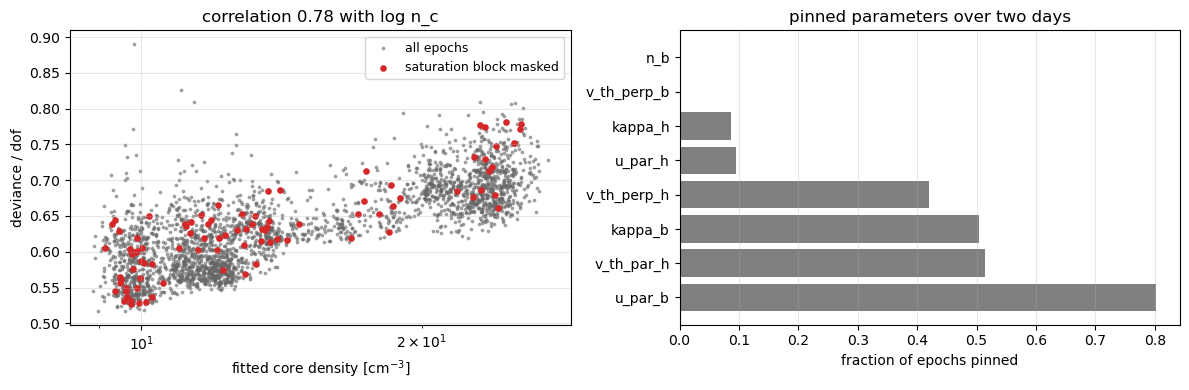

In [8]:
censusPath = DAYS_DIR / 'saturation_census.csv'
census = pd.read_csv(censusPath) if censusPath.exists() else None
if census is not None:
    days = days.merge(census[['epoch_ns', 'n_saturated_pixels']], on='epoch_ns', how='left')
    days['n_saturated_pixels'] = days['n_saturated_pixels'].fillna(0).astype(int)
    print(f"epochs with masked saturation blocks: {(days['n_saturated_pixels'] > 0).sum()} of {len(days)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(days['n_c'], days['deviance_per_dof'], s=3, color='0.4', alpha=0.5, label='all epochs')
if census is not None:
    masked = days['n_saturated_pixels'] > 0
    axes[0].scatter(days['n_c'][masked], days['deviance_per_dof'][masked], s=14, color='#d62728', label='saturation block masked')
axes[0].set_xscale('log'); axes[0].set_xlabel('fitted core density [cm$^{-3}$]'); axes[0].set_ylabel('deviance / dof')
axes[0].set_title('correlation %.2f with log n_c' % np.corrcoef(np.log(days['n_c']), days['deviance_per_dof'])[0, 1])
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
pinnedCounts = days['pinned_params'].fillna('').str.split(';').explode().value_counts().drop('', errors='ignore')
axes[1].barh(pinnedCounts.index, pinnedCounts.values / len(days), color='0.5')
axes[1].set_xlabel('fraction of epochs pinned'); axes[1].set_title('pinned parameters over two days'); axes[1].grid(alpha=0.3, axis='x')
fig.tight_layout()